# E4：L1 logistic regression 與係數稀疏性

問題：使用全部 150 個特徵的 L1 logistic regression，能否與現有全部特徵 L2、以及 E3 領先 pipeline 競爭？

主要設定：C ∈ {0.01, 0.1, 1, 10}，StandardScaler → L1 logistic regression，solver=saga，model seed=42，max_iter=10000，tol=1e-4。

此 notebook 是結果分析範本，不會訓練模型。
E4 的 config/factory/runner 擴充、四組實驗和係數輸出需先完成。
若你的實作使用不同的實驗名稱或設定欄位，先修改下方 manifest／CONFIG_FIELDS。
不會把缺少的實驗當成零分，也不會自動忽略收斂警告。


In [12]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (current, *current.parents)
     if (p / "configs").is_dir() and (p / "outputs" / "results").is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project directory.")

RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures" / "e4_l1_regularization"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Proposed directory names: edit to match the actual E4 experiment outputs.
EXPERIMENTS = [
    (0.01, "e4_l1_c_0_01"),
    (0.1, "e4_l1_c_0_1"),
    (1.0, "e4_l1_c_1"),
    (10.0, "e4_l1_c_10"),
]
REFERENCES = {
    "all_feature_l2": "logistic_c_0_001",
    "e3_leader": "e3_correlation_k_10_c_0_1",
}

# Map logical names to keys used by the E4 ExperimentConfig implementation.
# Use penalty='l1', or l1_ratio=1.0 with an appropriate sklearn version.
CONFIG_FIELDS = {
    "regularization_type": "regularization_type",
    "solver": "solver",
    "model_seed": "model_seed",
    "tol": "tol",
}
EXPECTED_REGULARIZATION = "l1"
# Example for an implementation using l1_ratio:
# CONFIG_FIELDS["regularization"] = "l1_ratio"
# EXPECTED_REGULARIZATION = 1.0

COEFFICIENT_THRESHOLD = 1e-8
C_VALUES = [c for c, _ in EXPERIMENTS]
print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification


## 預期輸出格式

每個 E4 目錄需要 config.json、summary.json、fold_scores.csv、repeat_scores.csv、split_indices.json、coefficient_records.json。

coefficient_records.json 是 list，每個 fold 一個 object：

```json
{
  "repeat": 0,
  "split_seed": 0,
  "fold": 0,
  "feature_names": ["feature_a", "feature_b"],
  "coefficients": [0.0, 0.12],
  "exact_nonzero_count": 1,
  "effective_nonzero_count": 1,
  "effective_nonzero_features": ["feature_b"],
  "n_iter": 100,
  "convergence_warning": false
}
```

上面只有兩個特徵作為格式示範；實驗需記錄全部 150 個特徵。
coefficients 可為長度 150 的 list 或二分類模型的 1×150 list。
n_iter 可為整數或單元素整數 list；convergence_warning 必須為布林值。
收斂警告必須由訓練程式實際捕捉，不能只因沒有達到迭代上限就寫成 false。


In [13]:
import sklearn

experiment_dir = RESULTS_DIR / "e4_l1_c_0_01"

actual_config = json.loads(
    (experiment_dir / "config.json").read_text(
        encoding="utf-8"
    )
)

print("Current scikit-learn version:", sklearn.__version__)
print("\nSaved experiment configuration:")
print(json.dumps(actual_config, indent=2))

print("\nNotebook field mapping:")
print(CONFIG_FIELDS)
print("Expected regularisation:", EXPECTED_REGULARIZATION)

Current scikit-learn version: 1.9.1

Saved experiment configuration:
{
  "experiment_id": "e4_l1_c_0_01",
  "data_config_path": "/Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/configs/data.json",
  "model_name": "logistic_regression",
  "regularization_c": 0.01,
  "max_iter": 10000,
  "n_splits": 5,
  "split_seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9
  ],
  "output_dir": "/Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/outputs/results/e4_l1_c_0_01",
  "feature_selection_k": null,
  "regularization_type": "l1",
  "solver": "saga",
  "model_seed": 42,
  "tol": 0.0001
}

Notebook field mapping:
{'regularization_type': 'regularization_type', 'solver': 'solver', 'model_seed': 'model_seed', 'tol': 'tol'}
Expected regularisation: l1


In [14]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

required_e4 = ["config.json", "summary.json", "fold_scores.csv", "repeat_scores.csv",
               "split_indices.json", "coefficient_records.json"]
required_reference = ["config.json", "fold_scores.csv", "repeat_scores.csv", "split_indices.json"]
missing = [str(RESULTS_DIR / name / filename) for _, name in EXPERIMENTS
           for filename in required_e4 if not (RESULTS_DIR / name / filename).is_file()]
missing += [str(RESULTS_DIR / name / filename) for name in REFERENCES.values()
            for filename in required_reference if not (RESULTS_DIR / name / filename).is_file()]
if missing:
    raise FileNotFoundError("Missing outputs; complete E4 or update the manifest:\n" + "\n".join(missing))

KEYS = ["repeat", "split_seed", "fold"]
expected_keys = pd.DataFrame([
    {"repeat": r, "split_seed": r, "fold": f}
    for r in range(10) for f in range(5)
])
expected_key_set = set(expected_keys.itertuples(index=False, name=None))
reference_splits = read_json(RESULTS_DIR / REFERENCES["all_feature_l2"] / "split_indices.json")
input_features = reference_splits["feature_names"]
if len(input_features) != 150 or len(set(input_features)) != 150:
    raise ValueError("Expected 150 unique input feature names.")


def validate_scores(directory):
    folds = pd.read_csv(directory / "fold_scores.csv")
    repeats = pd.read_csv(directory / "repeat_scores.csv")
    if len(folds) != 50 or folds[KEYS].duplicated().any():
        raise ValueError(f"Incomplete fold results: {directory.name}")
    pd.testing.assert_frame_equal(folds[KEYS].sort_values(KEYS).reset_index(drop=True),
                                  expected_keys, check_dtype=False)
    if not folds["valid_auc"].between(0, 1).all():
        raise ValueError(f"Invalid fold AUC: {directory.name}")
    if len(repeats) != 10 or repeats["split_seed"].duplicated().any():
        raise ValueError(f"Incomplete repetitions: {directory.name}")
    if not repeats["n_folds"].eq(5).all() or not repeats["mean_auc"].between(0, 1).all():
        raise ValueError(f"Invalid repeat results: {directory.name}")
    calculated = folds.groupby(["repeat", "split_seed"], as_index=False)["valid_auc"].mean()
    matched = repeats.merge(calculated, on=["repeat", "split_seed"], validate="one_to_one")
    if len(matched) != 10:
        raise ValueError(f"Mismatched repetition keys: {directory.name}")
    np.testing.assert_allclose(matched["mean_auc"], matched["valid_auc"], atol=1e-12, rtol=0)
    splits = read_json(directory / "split_indices.json")
    if splits["splits"] != reference_splits["splits"] or splits["feature_names"] != input_features:
        raise ValueError(f"Split or feature schema mismatch: {directory.name}")
    return repeats

reference_scores = {}
for label, name in REFERENCES.items():
    directory = RESULTS_DIR / name
    cfg = read_json(directory / "config.json")
    if cfg["n_splits"] != 5 or cfg["split_seeds"] != list(range(10)):
        raise ValueError(f"Unexpected reference validation settings: {name}")
    reference_scores[label] = validate_scores(directory)

repeat_tables = []
coefficient_rows = []
frequency_rows = []

for c, name in EXPERIMENTS:
    directory = RESULTS_DIR / name
    cfg = read_json(directory / "config.json")
    expected = {
        "regularization_c": c, "max_iter": 10000,
        "n_splits": 5, "split_seeds": list(range(10)),
        CONFIG_FIELDS["regularization_type"]: EXPECTED_REGULARIZATION,
        CONFIG_FIELDS["solver"]: "saga",
        CONFIG_FIELDS["model_seed"]: 42,
        CONFIG_FIELDS["tol"]: 1e-4,
    }
    for key, value in expected.items():
        if key not in cfg or cfg[key] != value:
            raise ValueError(f"Config mismatch for {key}: {name}. Check CONFIG_FIELDS and actual experiment settings.")
    if cfg.get("feature_selection_k") is not None:
        raise ValueError(f"E4 must not use correlation selection: {name}")

    repeats = validate_scores(directory)
    summary = read_json(directory / "summary.json")
    if summary["aggregation"] != "mean_fold_auc_per_repeat":
        raise ValueError(f"Unexpected aggregation: {name}")
    np.testing.assert_allclose(repeats["mean_auc"].mean(), summary["mean_auc"], atol=1e-12, rtol=0)
    np.testing.assert_allclose(repeats["mean_auc"].std(ddof=1), summary["std_auc"], atol=1e-12, rtol=0)
    repeat_tables.append(repeats.assign(C=c, experiment_id=name))

    records = read_json(directory / "coefficient_records.json")
    seen = set()
    selected_counts = dict.fromkeys(input_features, 0)
    if len(records) != 50:
        raise ValueError(f"Expected 50 coefficient records: {name}")
    for record in records:
        key = tuple(record[field] for field in KEYS)
        if key in seen or key not in expected_key_set:
            raise ValueError(f"Invalid coefficient record keys: {name}")
        seen.add(key)
        names = record["feature_names"]
        if names != input_features:
            raise ValueError(f"Coefficient feature order mismatch: {name}")
        coefficients = np.asarray(record["coefficients"], dtype=float)
        if coefficients.shape == (1, 150):
            coefficients = coefficients[0]
        if coefficients.shape != (150,) or not np.isfinite(coefficients).all():
            raise ValueError(f"Invalid coefficients: {name}")
        exact = int(np.count_nonzero(coefficients))
        mask = np.abs(coefficients) > COEFFICIENT_THRESHOLD
        effective = int(mask.sum())
        effective_names = [feature for feature, keep in zip(names, mask) if keep]
        if record["exact_nonzero_count"] != exact or record["effective_nonzero_count"] != effective:
            raise ValueError(f"Nonzero counts inconsistent with coefficients: {name}")
        if record["effective_nonzero_features"] != effective_names:
            raise ValueError(f"Effective feature names do not match threshold: {name}")
        iterations = np.asarray(record["n_iter"])
        if iterations.size != 1 or not np.issubdtype(iterations.dtype, np.integer):
            raise ValueError(f"Expected an integer binary-classification n_iter: {name}")
        iterations = int(iterations.item())
        if not 1 <= iterations <= cfg["max_iter"]:
            raise ValueError(f"Invalid n_iter: {name}")
        warning = record["convergence_warning"]
        if not isinstance(warning, bool):
            raise ValueError(f"convergence_warning must be boolean: {name}")
        coefficient_rows.append({"C": c, **dict(zip(KEYS, key)),
                                 "exact_nonzero_count": exact, "effective_nonzero_count": effective,
                                 "n_iter": iterations, "convergence_warning": warning,
                                 "hit_iteration_limit": iterations >= cfg["max_iter"]})
        for feature in effective_names:
            selected_counts[feature] += 1
    for feature, count in selected_counts.items():
        frequency_rows.append({"C": c, "feature": feature, "nonzero_folds": count,
                               "total_folds": 50, "nonzero_frequency": count / 50})

repeat_scores = pd.concat(repeat_tables, ignore_index=True)
coefficient_summary = pd.DataFrame(coefficient_rows)
feature_frequencies = pd.DataFrame(frequency_rows)
print("All structural checks passed. Convergence warnings are retained for review.")


All structural checks passed. Convergence warnings are retained for review.


## 1. AUC、稀疏性及收斂狀態

係數門檻固定為 |coefficient| > 1e-8，並另存精確非零數。
收斂警告或達到迭代上限的設定會被標示，不會自動刪除。
零係數結果仍須保留，不是程式錯誤的充分證據。


In [15]:
comparison = repeat_scores.groupby("C", as_index=False).agg(
    mean_auc=("mean_auc", "mean"), std_auc=("mean_auc", "std"),
    min_auc=("mean_auc", "min"), max_auc=("mean_auc", "max"))
sparsity = coefficient_summary.groupby("C", as_index=False).agg(
    mean_exact_nonzero=("exact_nonzero_count", "mean"),
    mean_effective_nonzero=("effective_nonzero_count", "mean"),
    min_effective_nonzero=("effective_nonzero_count", "min"),
    max_effective_nonzero=("effective_nonzero_count", "max"),
    all_zero_folds=("effective_nonzero_count", lambda x: int(x.eq(0).sum())),
    warning_folds=("convergence_warning", "sum"),
    iteration_limit_folds=("hit_iteration_limit", "sum"),
    max_n_iter=("n_iter", "max"))
comparison = comparison.merge(sparsity, on="C", validate="one_to_one")
comparison["numerical_review_required"] = (comparison["warning_folds"] > 0) | (comparison["iteration_limit_folds"] > 0)
paired = repeat_scores.copy()
for label, reference in reference_scores.items():
    control = reference[["repeat", "split_seed", "mean_auc"]].rename(columns={"mean_auc": f"{label}_auc"})
    paired = paired.merge(control, on=["repeat", "split_seed"], validate="many_to_one")
    if len(paired) != 40:
        raise ValueError("Reference pairing lost rows.")
    difference = f"difference_vs_{label}"
    paired[difference] = paired["mean_auc"] - paired[f"{label}_auc"]
    stats = paired.groupby("C", as_index=False).agg(**{
        f"mean_difference_vs_{label}": (difference, "mean"),
        f"sd_difference_vs_{label}": (difference, "std"),
        f"wins_vs_{label}": (difference, lambda x: int((x > 1e-12).sum())),
        f"losses_vs_{label}": (difference, lambda x: int((x < -1e-12).sum())),
        f"ties_vs_{label}": (difference, lambda x: int((x.abs() <= 1e-12).sum())),
    })
    comparison = comparison.merge(stats, on="C", validate="one_to_one")
comparison = comparison.sort_values("C").reset_index(drop=True)
display(comparison.round(6))
if comparison["numerical_review_required"].any():
    print("CAUTION: numerical review required for flagged candidates. Do not silently treat them as converged.")
comparison.to_csv(FIGURES_DIR / "e4_comparison.csv", index=False)
paired.to_csv(FIGURES_DIR / "e4_paired_repeat_scores.csv", index=False)
coefficient_summary.to_csv(FIGURES_DIR / "e4_fold_coefficient_summary.csv", index=False)
feature_frequencies.to_csv(FIGURES_DIR / "e4_feature_nonzero_frequencies.csv", index=False)


,C,mean_auc,std_auc,min_auc,max_auc,mean_exact_nonzero,mean_effective_nonzero,min_effective_nonzero,max_effective_nonzero,all_zero_folds,...,mean_difference_vs_all_feature_l2,sd_difference_vs_all_feature_l2,wins_vs_all_feature_l2,losses_vs_all_feature_l2,ties_vs_all_feature_l2,mean_difference_vs_e3_leader,sd_difference_vs_e3_leader,wins_vs_e3_leader,losses_vs_e3_leader,ties_vs_e3_leader
0,0.01,0.500000,0.000000,0.500000,0.500000,0.00,0.00,0,0,50,...,-0.293999,0.009091,0,10,0,-0.322982,0.008456,0,10,0
1,0.10,0.852864,0.010803,0.838038,0.876227,15.76,15.76,11,22,0,...,0.058865,0.008286,10,0,0,0.029882,0.010501,10,0,0
2,1.00,0.862112,0.012204,0.844883,0.878112,74.96,74.96,64,85,0,...,0.068113,0.012379,10,0,0,0.039130,0.015253,10,0,0
3,10.00,0.817571,0.015909,0.790680,0.842070,97.06,97.06,85,107,0,...,0.023573,0.016327,9,1,0,-0.005411,0.019133,3,7,0


## 2. C 與 AUC、非零係數數量

左圖誤差棒為跨重複標準差，不是信賴區間。
右圖每點為單一訓練折的有效非零係數數；黑線是 50 折平均。
兩種圖的統計單位不同，不要把係數數量的折分布當成獨立樣本。


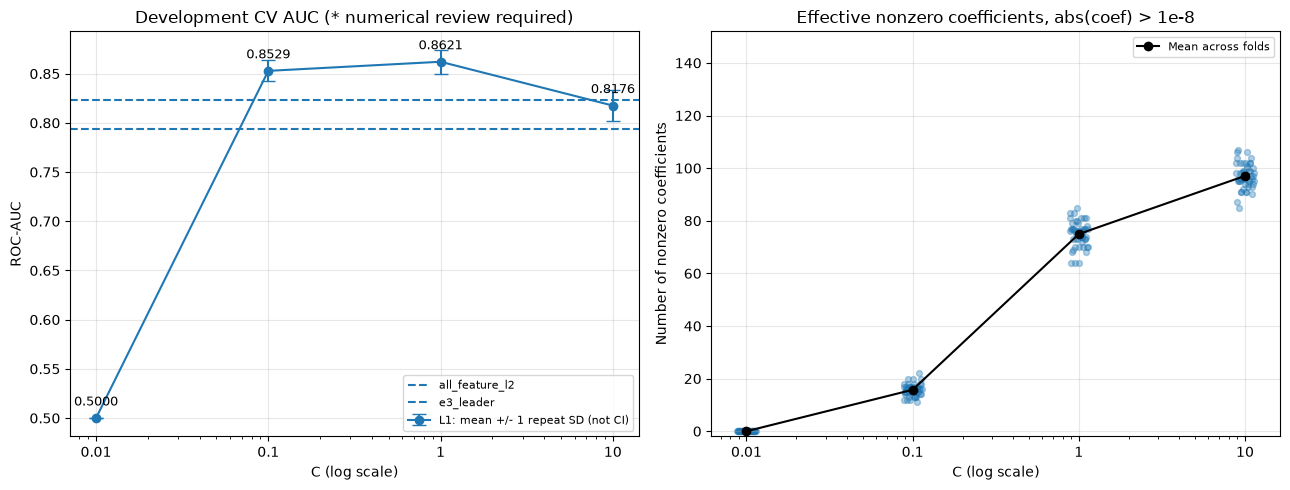

In [16]:
def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURES_DIR / f"{name}.pdf", bbox_inches="tight")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].errorbar(comparison["C"], comparison["mean_auc"], yerr=comparison["std_auc"],
                 fmt="o-", capsize=5, label="L1: mean +/- 1 repeat SD (not CI)")
for label, reference in reference_scores.items():
    axes[0].axhline(reference["mean_auc"].mean(), linestyle="--", label=label)
for row in comparison.itertuples(index=False):
    suffix = "*" if row.numerical_review_required else ""
    axes[0].annotate(f"{row.mean_auc:.4f}{suffix}", (row.C, row.mean_auc),
                     xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
axes[0].set_title("Development CV AUC (* numerical review required)")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(fontsize=8)
for c, group in coefficient_summary.groupby("C"):
    offsets = np.linspace(-0.055, 0.055, len(group))
    axes[1].scatter(c * 10**offsets, group["effective_nonzero_count"], alpha=0.35, s=18, color="tab:blue")
axes[1].plot(comparison["C"], comparison["mean_effective_nonzero"], "ko-", label="Mean across folds")
axes[1].set_title("Effective nonzero coefficients, abs(coef) > 1e-8")
axes[1].set_ylabel("Number of nonzero coefficients")
axes[1].set_ylim(-2, 152)
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(C_VALUES)
    ax.set_xticklabels([f"{c:g}" for c in C_VALUES])
    ax.set_xlabel("C (log scale)")
    ax.grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "e4_auc_and_sparsity")
plt.show()


## 3. 相對兩個參考 pipeline 的配對差值

每點是一個重複驗證的差值，黑色菱形是平均值。
正值偏向 L1；兩個子圖的對照不同。
同一批資料被重複使用，這不是顯著性檢定，也不是獨立確認。


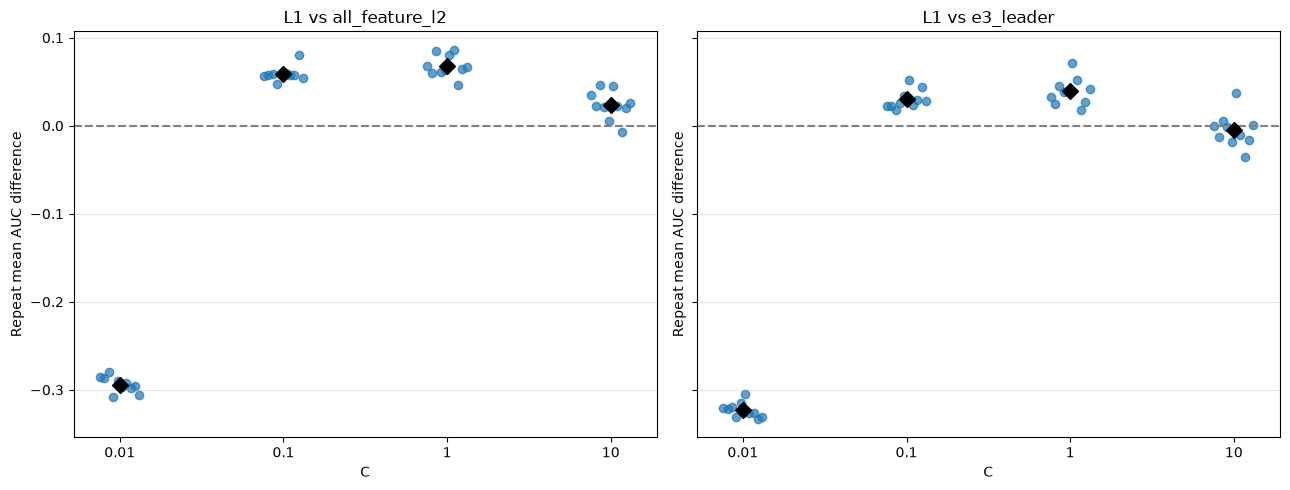

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, label in zip(axes, REFERENCES):
    for position, c in enumerate(C_VALUES):
        values = paired.loc[paired["C"].eq(c)].sort_values("split_seed")[f"difference_vs_{label}"].to_numpy()
        ax.scatter(position + np.linspace(-0.12, 0.12, len(values)), values, alpha=0.7, color="tab:blue")
        ax.scatter(position, values.mean(), marker="D", s=65, color="black", zorder=3)
    ax.axhline(0, linestyle="--", color="gray")
    ax.set_xticks(range(len(C_VALUES)))
    ax.set_xticklabels([f"{c:g}" for c in C_VALUES])
    ax.set_xlabel("C")
    ax.set_ylabel("Repeat mean AUC difference")
    ax.set_title(f"L1 vs {label}")
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
save_figure(fig, "e4_paired_differences")
plt.show()


## 4. 係數非零頻率與數值診斷

非零頻率是 50 個相互重疊訓練折的描述，不是 bootstrap，也不是因果證據。
不能僅因保留較少係數就宣稱模型較好。


In [18]:
diagnostics = coefficient_summary.loc[
    coefficient_summary["convergence_warning"] | coefficient_summary["hit_iteration_limit"]
]
print("Folds requiring numerical review:")
display(diagnostics)
DISPLAY_C = 0.1
print(f"Top 20 effective nonzero frequencies for C={DISPLAY_C}")
display(feature_frequencies.loc[feature_frequencies["C"].eq(DISPLAY_C)].sort_values(
    ["nonzero_frequency", "feature"], ascending=[False, True]
).head(20).reset_index(drop=True))
print(f"Figures and tables saved to: {FIGURES_DIR}")


Folds requiring numerical review:


,C,repeat,split_seed,fold,exact_nonzero_count,effective_nonzero_count,n_iter,convergence_warning,hit_iteration_limit


Top 20 effective nonzero frequencies for C=0.1


,C,feature,nonzero_folds,total_folds,nonzero_frequency
0,0.1,100,50,50,1.00
1,0.1,138,50,50,1.00
2,0.1,46,50,50,1.00
3,0.1,80,50,50,1.00
4,0.1,30,49,50,0.98
5,0.1,67,49,50,0.98
6,0.1,108,48,50,0.96
7,0.1,17,40,50,0.80
8,0.1,116,39,50,0.78
9,0.1,117,34,50,0.68


Figures and tables saved to: /Users/moli/Documents/coding/DSAI4203_Project/small_sample_classification/outputs/figures/e4_l1_regularization


## 5. 結論紀錄（執行後填寫）

- 四組實驗的收斂狀態：待填。
- L1 的平均 AUC 與配對結果：待填。
- 是否有候選值得取代 E3 pipeline：待填。
- AUC 與有效非零係數數量的關係：待填。
- 零係數或失敗結果：如實記錄，不刪除。
- 是否需要數值診斷重跑或選做同 solver 的 L2 對照：待填。

本輪比較完整方案；相對舊基準同時改變了正則化形式、solver 和數值設定，不能將差異全部歸因於 L1。
E3 領先模型已經過探索選出，本輪也使用同一批觀察值，因此不是獨立最終評估。
先完成這四組，再決定是否做 Elastic-net，不自動擴充 C 範圍。
